## Read the data

In [30]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

# 1. Read data (Now it is the same data)

In [31]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/groups_retrain_single_allele_balanced_data/" #!CHANGE
APPROACH = "DECOY_PATHS"

In [32]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
          ]
ALLELES = [
    'HLA-A*01:01',
    'HLA-A*03:01',
    # 'HLA-A*02:01б'
   'HLA-DRB1*01:01'

          ]
selected_alleles = ALLELES
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-DRB1*01:01']

## 2.0 Merge alleles together

In [33]:
# combination_size = len(ALLELES)
ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'])
# ALLELES = sorted([ 'HLA-A*03:01'])

ALLELES = sorted(['HLA-DRB1*01:01'])


combination_size = 1
TOTAL_SPLITS = 1
TARGET_LENGTHS= [10, 11, 12,13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [8, 9, 10, 11, 12]
RUNS = 2
USE_WEIGHTS = True

# SELECTED_RUN = 0
# SELECTED_RUN = {0,1,2,3,4,5, 6, 7, 8, 9}
SELECTED_RUN = {0,1}

# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0
models_to_read = ['bw']

In [34]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DRB1*01:01
Length 8: HLA-DRB1*01:01 - 39 
Length 9: HLA-DRB1*01:01 - 113 
Length 10: HLA-DRB1*01:01 - 123 
Length 11: HLA-DRB1*01:01 - 175 
Length 12: HLA-DRB1*01:01 - 368 
Length 13: HLA-DRB1*01:01 - 826 
Length 14: HLA-DRB1*01:01 - 1184 
Length 15: HLA-DRB1*01:01 - 6886 
Length 16: HLA-DRB1*01:01 - 1413 
Length 17: HLA-DRB1*01:01 - 984 
Length 18: HLA-DRB1*01:01 - 708 
Length 19: HLA-DRB1*01:01 - 316 
Length 20: HLA-DRB1*01:01 - 505 
Length 21: HLA-DRB1*01:01 - 177 
Length 22: HLA-DRB1*01:01 - 80 
Length 23: HLA-DRB1*01:01 - 57 
Length 24: HLA-DRB1*01:01 - 67 
Length 25: HLA-DRB1*01:01 - 50 
Length 26: HLA-DRB1*01:01 - 15 
Length 27: HLA-DRB1*01:01 - 12 
Length 28: HLA-DRB1*01:01 - 8 
Length 30: HLA-DRB1*01:01 - 7 


## Calculate weights for data

In [35]:
TARGET_LENGTHS

[10, 11, 12, 13, 14, 15, 16, 17, 18]

In [36]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [37]:
per_allele_per_kfold_per_length_weights = \
    calculate_weights_based_on_length_counts(count_df_train,
                                             selected_alleles=ALLELES,
                                             total_splits=TOTAL_SPLITS,
                                             selected_lengths=TARGET_LENGTHS,
                                             use_weights=USE_WEIGHTS)

Total data length for split 0 is 12667
Weights for lentgh 10 are {'HLA-DRB1*01:01': 102.98373983739837}
Weights for lentgh 11 are {'HLA-DRB1*01:01': 72.38285714285715}
Weights for lentgh 12 are {'HLA-DRB1*01:01': 34.421195652173914}
Weights for lentgh 13 are {'HLA-DRB1*01:01': 15.335351089588377}
Weights for lentgh 14 are {'HLA-DRB1*01:01': 10.69847972972973}
Weights for lentgh 15 are {'HLA-DRB1*01:01': 1.83952948010456}
Weights for lentgh 16 are {'HLA-DRB1*01:01': 8.964614295824488}
Weights for lentgh 17 are {'HLA-DRB1*01:01': 12.872967479674797}
Weights for lentgh 18 are {'HLA-DRB1*01:01': 17.891242937853107}


In [38]:
count_df_train

cnt
allele         split length      
HLA-DRB1*01:01 0     8         39
                     9        113
                     10       123
                     11       175
                     12       368
                     13       826
                     14      1184
                     15      6886
                     16      1413
                     17       984
                     18       708
                     19       316
                     20       505
                     21       177
                     22        80
                     23        57
                     24        67
                     25        50
                     26        15
                     27        12
                     28         8
                     30         7

# Read models

In [39]:
MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10, 11, 12]
    },
    "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },

        "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 49,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },

    "multiple_allele_balanced_longer_training": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "100-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },

    "groups_retrain_single_allele_balanced_data": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/",
        "states": 45,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]}
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [40]:
MODELS_DESCRIPTIONS.keys()

dict_keys(['single_allele_imbalanced', 'single_allele_balanced', 'multiple_allele_balanced', 'single_allele_balanced_class2', 'single_allele_balanced_class2_biger', 'multiple_allele_imbalanced', 'multiple_allele_balanced_longer_training', 'mix_of_alleles', 'groups_retrain_single_allele_balanced_data'])

In [41]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                   # 'multiple_allele_balanced',
    # "single_allele_balanced_class2",
        "groups_retrain_single_allele_balanced_data"
    # 'multiple_allele_balanced_longer_training'
]


In [42]:
from hmm_logic_methods import load_model

In [43]:
import itertools
import mhcnames

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    model_alleles = set(model_alleles).intersection(set(ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [44]:
list(per_name_binding_model.keys())

['0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0']

## 2.2 Train
### 2.2.1 Define treshold

In [45]:
stop_threshold = 0
cutoff = 0.0005
per_symbol_portion = -100 / 9
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

117.44135802469135

In [46]:
import logomaker
from collections import defaultdict
def probs_to_info_matrix(distribution):
    amino_acids = list(distribution.parameters[0].keys())
    dummy_df = pd.DataFrame(columns = sorted(amino_acids), index=[0],  dtype=float)
    for i, (acid, prob) in enumerate(distribution.parameters[0].items()):
        dummy_df.loc[0, acid] = prob
    dummy_df.index.name = "pos"
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    return info_matrix



for model_key, model in per_name_binding_model.items():
    per_state_information = dict()
    per_level_information = defaultdict(float)

    for state in model.states:
        if state not in [model.start, model.end]:
            info_matrix = probs_to_info_matrix(state.distribution)
            per_state_information[state.name] = sum(info_matrix.loc[0])
            # per_level_information[name_to_level[state.name]] += per_state_information[state.name]
    break

In [47]:
df = pd.DataFrame(per_state_information.items(), columns=["state", "info"])

In [48]:
df.sort_values(by='info', ascending=False)

,state,info
27,s027,2.230645
29,s029,2.151597
14,s014,2.140457
25,s025,1.871921
20,s020,1.732298
38,s038,1.592687
10,s010,1.527813
28,s028,1.385195
40,s040,1.350485
17,s017,1.245946


## Calculate viterbi paths for train data (Try to find anchors)

In [49]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [51]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences
allele_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(model, allele_peptides)


Model 0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 12667/12667 [00:01<00:00, 10292.21it/s]


Select unique paths...
	Unique paths: 11714


100%|██████████| 11714/11714 [00:00<00:00, 35700.07it/s]


In [52]:
allele_bw_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s001>s005>s014>s013>s015>s...,-10.002307,-0.714451,12,-34.795086,3
1,grouped_model-start>s003>s007>s005>s014>s013>s...,-10.791529,-0.719435,13,-42.684984,1
2,grouped_model-start>s004>s009>s007>s005>s014>s...,-11.579876,-0.723742,14,-39.344564,1
3,grouped_model-start>s003>s007>s005>s014>s013>s...,-10.877871,-0.725191,13,-36.525293,2
4,grouped_model-start>s000>s001>s005>s014>s013>s...,-10.894956,-0.726330,13,-37.903886,1
...,...,...,...,...,...,...
11709,grouped_model-start>s000>s009>s012>s017>s023>s...,-27.080313,-1.592960,15,-53.481328,1
11710,grouped_model-start>s003>s008>s014>s011>s018>s...,-27.232899,-1.601935,15,-54.368034,1
11711,grouped_model-start>s002>s000>s002>s001>s006>s...,-27.282463,-1.604851,15,-59.117454,1
11712,grouped_model-start>s003>s004>s009>s007>s008>s...,-28.499659,-1.676451,15,-56.238231,1


In [66]:
state_names = [f"s{i:03d}".format(i) for i in range(len(model.states) - 2)] # minus start minus end

# allele_bw_paths_df.loc[:,state_names] = 0

per_state_counts = dict()

In [67]:
for state_name in state_names:
    per_state_counts[state_name] =  allele_bw_paths_df[allele_bw_paths_df['path'].str.contains(state_name)]['peptide_cnts'].sum()


In [68]:
per_state_counts

{'s000': 4215,
 's001': 4885,
 's002': 3780,
 's003': 2513,
 's004': 5635,
 's005': 6680,
 's006': 2045,
 's007': 6424,
 's008': 3834,
 's009': 3114,
 's010': 2078,
 's011': 2275,
 's012': 2398,
 's013': 8064,
 's014': 8126,
 's015': 6469,
 's016': 2003,
 's017': 1406,
 's018': 1941,
 's019': 2266,
 's020': 8900,
 's021': 5908,
 's022': 1625,
 's023': 3999,
 's024': 1478,
 's025': 722,
 's026': 1966,
 's027': 5314,
 's028': 2436,
 's029': 3851,
 's030': 7591,
 's031': 1568,
 's032': 6300,
 's033': 2569,
 's034': 3135,
 's035': 3362,
 's036': 4899,
 's037': 3494,
 's038': 8420,
 's039': 2492,
 's040': 5131,
 's041': 2712,
 's042': 5215,
 's043': 4777,
 's044': 7069}

In [69]:
import seaborn as sns

In [84]:
df = pd.DataFrame.from_dict(per_state_counts, orient='index', columns=['cnt'])

# sns.barplot(x=list(per_state_counts.keys()), y=list(per_state_counts.values()))

<AxesSubplot:>

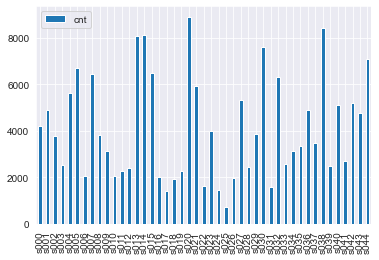

In [85]:
df.plot(kind='bar')

In [87]:
df.sort_values(by='cnt', ascending=False)

,cnt
s020,8900
s038,8420
s014,8126
s013,8064
s030,7591
s044,7069
s005,6680
s015,6469
s007,6424
s032,6300
